# Does Brazilian weather predict soybean futures returns?

**Machine Learning for Portfolio Management and Trading — research notebook**  
**Commodity:** Soybeans · **Country of weather observations:** Brazil · **Price:** CBOT soybean futures, `ZS=F` (Yahoo Finance)

### Research hypotheses

- **H1 — Forecasting:** lagged rainfall and temperature anomalies in Brazilian soybean regions improve next-week return forecasts relative to price-based predictors.
- **H2 — Seasonality:** weather signals have greater predictive value during the Brazilian growing season (October–March, a simplified proxy).
- **H3 — Trading:** the incremental forecasts improve a position-based strategy **after transaction costs**.

**Design.** Weekly observations; temperature and rainfall in five Brazilian production areas (Open-Meteo ERA5); fixed pre-test weekly climatology; Ridge regression; chronologically expanding out-of-sample evaluation starting January 2022; identical splits and trading rules across models; HAC uncertainty diagnostics.

**Important:** `ZS=F` is a *Chicago* futures quote, **not a Brazilian farmgate price**. Its historical Yahoo series may combine contracts without a fully tradeable, roll-adjusted methodology. Accordingly, the trading study is illustrative, not a claim of implementable profits. A weather–return association does not establish a causal effect.

This is a **new empirical hypothesis and dataset** rather than a reproduction of the original natural-gas strategy. The original notebook used ideas from [marius-stos/weather-commodity-strategy](https://github.com/marius-stos/weather-commodity-strategy); **no code or trading rules from that strategy are used in the present experiment**.

## 1. Reproducibility and configuration

Run **Kernel → Restart & Run All**, with an internet connection on the first run. The download cells save CSVs in `data_cache_soy/`; subsequent runs reuse those files. For the final submission, keep the cached CSVs together with the notebook, or ensure both APIs are accessible. Fixed dates make the empirical horizon explicit, although Yahoo may revise its historical continuous-futures series.

In [1]:
# Run once in a fresh Jupyter kernel; installation may require a kernel restart.
%pip install -q "numpy>=1.24" "pandas>=2.0" "matplotlib>=3.7" "requests>=2.31" "yfinance>=0.2.50" "scikit-learn>=1.3" "statsmodels>=0.14"

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
import yfinance as yf
import statsmodels.api as sm
from IPython.display import display
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_squared_error

pd.set_option('display.max_columns', 25)
plt.rcParams.update({'figure.figsize': (11, 4.2), 'axes.grid': True, 'grid.alpha': 0.20})

START = '2014-01-01'
END = '2026-10-31'                # fixed cutoff; the weather archive has a publication lag
CLIM_END = '2020-12-31'            # fixed climatology fitted before the 2022 test period
TEST_START = '2022-01-01'
TICKER = 'ZS=F'                   # soybean futures in cents/bushel, CBOT (not local Brazil)
REFIT_EVERY = 4                  # re-estimate expanding Ridge every four weeks
RIDGE_ALPHA = 10.0               # fixed in advance, no optimization on the test set
POSITION_SCALE = 0.02            # 2% expected weekly return -> full long exposure
TRANSACTION_COST = 0.0005        # hypothetical 5bp per unit change in exposure
CACHE = Path('data_cache_soy')
CACHE.mkdir(exist_ok=True)

# Representative agricultural locations, NOT production-weighted state-level averages.
CITIES = {
    'Mato_Grosso_Sorriso': (-12.55, -55.72),
    'Goias_Rio_Verde': (-17.79, -50.92),
    'Mato_Grosso_do_Sul_Dourados': (-22.22, -54.81),
    'Parana_Cascavel': (-24.96, -53.46),
    'Rio_Grande_do_Sul_Passo_Fundo': (-28.26, -52.41),
}
print(f'{TICKER}: {START} to {END}; test >= {TEST_START}; {len(CITIES)} Brazilian locations')

ZS=F: 2014-01-01 to 2026-10-31; test >= 2022-01-01; 5 Brazilian locations


## 2. Download public data

**Weather.** Open-Meteo [Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), **ERA5**, daily precipitation (`mm`) and 2m mean temperature (`°C`), in the time zone `America/Sao_Paulo`. ERA5 observations are reanalyses published with an approximate five-day lag; this notebook **lags weekly weather features one full week** before using them to forecast.

**Futures.** Yahoo Finance [`ZS=F`](https://finance.yahoo.com/quote/ZS=F/history/), obtained via `yfinance`. Close prices are resampled to Friday-ending weeks. No credentials or manual CSV preparation are required. Weather observations for the five coordinates are proxies and cannot reproduce Brazilian national production conditions exactly.

In [3]:
session = requests.Session()
retry = Retry(total=3, connect=3, read=3, backoff_factor=1,
              status_forcelist=(429, 500, 502, 503, 504))
session.mount('https://', HTTPAdapter(max_retries=retry))

def get_era5_daily(name, lat, lon):
    path = CACHE / f'ERA5_{name}_{START}_{END}.csv'
    if path.exists():
        df = pd.read_csv(path, index_col=0, parse_dates=True)
    else:
        endpoint = 'https://archive-api.open-meteo.com/v1/archive'
        params = dict(latitude=lat, longitude=lon, start_date=START, end_date=END,
                      daily='temperature_2m_mean,precipitation_sum',
                      timezone='America/Sao_Paulo', models='era5')
        response = session.get(endpoint, params=params, timeout=90)
        response.raise_for_status()
        payload = response.json()
        if 'daily' not in payload:
            raise ValueError(f'Open-Meteo failed for {name}: {str(payload)[:300]}')
        df = pd.DataFrame(payload['daily']).set_index('time')
        df.index = pd.to_datetime(df.index)
        df = df[['temperature_2m_mean', 'precipitation_sum']].apply(pd.to_numeric, errors='coerce')
        df.to_csv(path)
    df = df.sort_index()
    if df.isna().mean().max() > .05:
        raise ValueError(f'Too many missing values in weather for {name}')
    return df

weather_daily = {name: get_era5_daily(name, *coords) for name, coords in CITIES.items()}
print('Open-Meteo:', len(weather_daily), 'locations /',
      min(v.index.min() for v in weather_daily.values()).date(),
      'to', max(v.index.max() for v in weather_daily.values()).date())

Open-Meteo: 5 locations / 2014-01-01 to 2026-10-31


In [4]:
price_file = CACHE / f'Yahoo_{TICKER.replace("=", "_")}_{START}_{END}.csv'
if price_file.exists():
    price = pd.read_csv(price_file, index_col=0, parse_dates=True).iloc[:, 0]
else:
    # Yahoo `end` is exclusive; include the fixed cutoff date.
    end_exclusive = (pd.Timestamp(END) + pd.Timedelta(days=1)).strftime('%Y-%m-%d')
    raw = yf.download(TICKER, start=START, end=end_exclusive, auto_adjust=False,
                      progress=False, threads=False)
    if raw.empty or 'Close' not in raw.columns:
        raise RuntimeError('Yahoo returned no soybean prices. Retry or inspect the ticker and connection.')
    close = raw['Close']
    if isinstance(close, pd.DataFrame):
        close = close.iloc[:, 0]
    price = pd.to_numeric(close, errors='coerce').rename('soy_close')
    price.index = pd.DatetimeIndex(price.index).tz_localize(None).normalize()
    price = price[~price.index.duplicated(keep='last')].dropna().sort_index()
    price.to_frame().to_csv(price_file)
price = price.astype(float).rename('soy_close').sort_index()
if len(price) < 500 or (price <= 0).any():
    raise ValueError(f'Insufficient / invalid futures data: {len(price)} daily observations.')
print('Yahoo price observations:', len(price), 'from', price.index.min().date(), 'to', price.index.max().date())
display(price.tail().to_frame())

Yahoo price observations: 3226 from 2014-01-02 to 2026-10-30


,soy_close
Date,
2026-10-26,1241.25
2026-10-27,1229.25
2026-10-28,1224.50
2026-10-29,1219.75
2026-10-30,1222.25


## 3. Build *point-in-time* weather indicators

A weekly anomaly is the deviation from the **same ISO week**'s average measured in the fixed reference period 2014–2020. The reference period ends **before** the out-of-sample evaluation. Precipitation is summed within each Friday-ending week; temperature is averaged. We keep the ten state/variable anomalies and two four-week regional aggregates, then **shift them by one week** to respect ERA5 publication delay.

For example, to form a signal after the Friday close at `t`, we use weather through Friday `t−7 days` at the latest. More detailed crop calendars and within-state spatial sampling would be useful extensions.

In [5]:
# 5 regions x (precipitation, temperature), with Friday-ending weeks.
weather_weekly = pd.concat({name: df.resample('W-FRI').agg({
    'temperature_2m_mean': 'mean',
    'precipitation_sum': 'sum'
}) for name, df in weather_daily.items()}, axis=1).sort_index()

# Fixed pre-test weekly climatology (week 53 grouped with week 52).
def week_number(index):
    return pd.Series(np.minimum(index.isocalendar().week.to_numpy(dtype=int), 52), index=index)

week_ids = week_number(weather_weekly.index)
ref = weather_weekly.loc[:CLIM_END]
ref_ids = week_number(ref.index)
clim = ref.groupby(ref_ids).mean()
if clim.shape[0] < 52:
    raise ValueError('Climatology has too few weeks; check downloaded ERA5 data.')

anomalies = pd.DataFrame(index=weather_weekly.index)
for region in CITIES:
    for variable, abbrev in [('precipitation_sum', 'rain'), ('temperature_2m_mean', 'temp')]:
        actual = weather_weekly[(region, variable)]
        normal = week_ids.map(clim[(region, variable)])
        anomalies[f'{region}_{abbrev}'] = actual - normal

rain_cols = [f'{region}_rain' for region in CITIES]
temp_cols = [f'{region}_temp' for region in CITIES]
anomalies['Brazil_rain_4w'] = anomalies[rain_cols].mean(axis=1).rolling(4, min_periods=4).mean()
anomalies['Brazil_temp_4w'] = anomalies[temp_cols].mean(axis=1).rolling(4, min_periods=4).mean()

# The weekly weather ending at t-7 days is known by decision Friday t under ERA5's ~5d delay.
X_weather = anomalies.shift(1).add_prefix('lagged_')
print('Weather predictors:', len(X_weather.columns))
display(X_weather.iloc[-4:, :6])

Weather predictors: 12


,lagged_Mato_Grosso_Sorriso_rain,lagged_Mato_Grosso_Sorriso_temp,lagged_Goias_Rio_Verde_rain,lagged_Goias_Rio_Verde_temp,lagged_Mato_Grosso_do_Sul_Dourados_rain,lagged_Mato_Grosso_do_Sul_Dourados_temp
time,,,,,,
2026-10-16,5.214286,0.138776,21.985714,-2.673469,33.314286,-2.971429
2026-10-23,5.800000,-0.346939,12.571429,-3.140816,50.628571,-4.593878
2026-10-30,-17.757143,1.412245,-25.571429,-1.300000,-45.085714,-2.318367
2026-11-06,-16.171429,1.328571,-11.600000,-0.218367,-5.914286,-3.718367


## 4. Common forecasting dataset: same observation dates, no target leakage

At the close of Friday `t`, forecasts target the futures **close-to-close return from `t` to `t+1`**. The comparison uses a common set of dates. The market-only model includes last week's return, 4-week momentum, 8-week volatility and annual calendar controls; the augmented models add weather anomalies and weather × growing-season interactions.

**Execution simplification:** predicting at Friday close and earning the immediately following close-to-close return assumes trading at that close. In live trading one would need a realistic next-session execution/settlement convention; this remains a research backtest.

In [6]:
weekly_price = price.resample('W-FRI').last().dropna().rename('soy_close')
weekly_return = weekly_price.pct_change(fill_method=None).rename('weekly_ret')

idx = weekly_price.index
is_growing = pd.Series(idx.month.isin([10, 11, 12, 1, 2, 3]).astype(int),
                       index=idx, name='growing_season')
X_market = pd.DataFrame(index=idx)
X_market['ret_1w'] = weekly_return
X_market['ret_2w_lagged'] = weekly_return.shift(1)
X_market['momentum_4w'] = weekly_price.pct_change(4)
X_market['volatility_8w'] = weekly_return.rolling(8, min_periods=8).std()
X_market['calendar_sin'] = np.sin(2 * np.pi * idx.dayofyear / 365.25)
X_market['calendar_cos'] = np.cos(2 * np.pi * idx.dayofyear / 365.25)
X_market['growing_season'] = is_growing

X_weather = X_weather.reindex(idx)
X_season = X_weather.mul(is_growing, axis=0).add_prefix('growing_x_')
X_all = pd.concat([X_market, X_weather, X_season], axis=1)

# y_t is realized between close t and close t+1; this is not observed when deciding at t.
y = weekly_return.shift(-1).rename('next_week_ret')
data = pd.concat([X_all, y], axis=1).dropna().sort_index()
market_cols = list(X_market.columns)
weather_cols = list(X_weather.columns)
season_cols = list(X_season.columns)
FEATURES = {
    'Market': market_cols,
    'Weather': market_cols + weather_cols,
    'Weather + season': market_cols + weather_cols + season_cols,
}
if len(data.loc[:'2021-12-31']) < 150 or len(data.loc[TEST_START:]) < 50:
    raise ValueError('Insufficient train/test dates; inspect data alignment and API responses.')
assert data.index.is_unique and data.notna().all().all()
print(f'Complete weekly observations: {len(data)} (training: {(data.index < TEST_START).sum()}, '
      f'test: {(data.index >= TEST_START).sum()})')
print('Feature counts:', {k: len(v) for k, v in FEATURES.items()})
display(data[['ret_1w', 'lagged_Brazil_rain_4w', 'lagged_Brazil_temp_4w', 'next_week_ret']].tail())

Complete weekly observations: 661 (training: 410, test: 251)
Feature counts: {'Market': 7, 'Weather': 19, 'Weather + season': 31}


/var/folders/dk/htj2bvb523g8gdypchzqq5vc0000gn/T/ipykernel_35569/3130823909.py:12: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  X_market['calendar_sin'] = np.sin(2 * np.pi * idx.dayofyear / 365.25)
/var/folders/dk/htj2bvb523g8gdypchzqq5vc0000gn/T/ipykernel_35569/3130823909.py:13: Pandas4Warning: DatetimeIndex.dayofyear is deprecated and will be removed in a future version. Use DatetimeIndex.day_of_year instead.
  X_market['calendar_cos'] = np.cos(2 * np.pi * idx.dayofyear / 365.25)


,ret_1w,lagged_Brazil_rain_4w,lagged_Brazil_temp_4w,next_week_ret
Date,,,,
2026-09-25,0.011891,15.604286,-1.303673,-0.030895
2026-10-02,-0.030895,23.382143,-1.470306,0.010757
2026-10-09,0.010757,18.762857,-1.515714,-0.023800
2026-10-16,-0.023800,14.657857,-1.061531,-0.003766
2026-10-23,-0.003766,24.866429,-1.088061,-0.027258


## 5. H1 — expanding walk-forward forecasting

At each date `t` in the test period, train Ridge only on weeks whose target has already been realized. Re-estimate every four weeks on an **expanding history**, with `StandardScaler` fitted exclusively on each training window. We do **not** select models or tune their hyperparameters on the test sample. The market-only model is the benchmark; the zero-forecast is also reported.

Forecast metrics: mean squared error (MSE), predictive out-of-sample `R²` relative to zero, and directional accuracy. Since forecast comparison is serially dependent, the notebook also computes a Newey–West/HAC test for the mean squared-error difference. Small p-values should not be mistaken for causal evidence or corrected multiple testing.

In [7]:
def expanding_forecast(frame, feature_names, start_date=TEST_START, refit_every=REFIT_EVERY):
    first = frame.index.searchsorted(pd.Timestamp(start_date), side='left')
    X = frame[feature_names]
    y_obs = frame['next_week_ret']
    pred = pd.Series(np.nan, index=frame.index, name='forecast', dtype=float)
    for i in range(first, len(frame), refit_every):
        # For a forecast at Friday i, the preceding target ends no later than Friday i.
        train_X, train_y = X.iloc[:i], y_obs.iloc[:i]
        model = make_pipeline(StandardScaler(), Ridge(alpha=RIDGE_ALPHA))
        model.fit(train_X, train_y)
        stop = min(i + refit_every, len(frame))
        pred.iloc[i:stop] = model.predict(X.iloc[i:stop])
    return pred.loc[start_date:]

predictions = pd.DataFrame({
    name: expanding_forecast(data, cols) for name, cols in FEATURES.items()
})
oos = pd.concat([data[['next_week_ret', 'growing_season']].loc[TEST_START:], predictions], axis=1).dropna()
assert len(oos) == len(data.loc[TEST_START:]) and oos.index.is_unique
print('OOS period:', oos.index[0].date(), 'to', oos.index[-1].date(), '| N =', len(oos))
display(oos.tail())

OOS period: 2022-01-07 to 2026-10-23 | N = 251


,next_week_ret,growing_season,Market,Weather,Weather + season
Date,,,,,
2026-09-25,-0.030895,0,0.001231,0.000937,0.002759
2026-10-02,0.010757,1,0.004146,0.003181,0.005656
2026-10-09,-0.023800,1,-0.002773,-0.004619,0.008199
2026-10-16,-0.003766,1,0.004573,0.008712,0.007628
2026-10-23,-0.027258,1,0.001035,0.008086,0.003029


In [8]:
def forecast_metrics(pred, truth):
    mse = mean_squared_error(truth, pred)
    mse0 = np.mean(np.square(truth))
    return pd.Series({
        'MSE': mse,
        'R² vs forecast=0': 1 - mse / mse0,
        'Direction accuracy': (np.sign(pred) == np.sign(truth)).mean(),
        'Correlation': (np.corrcoef(pred, truth)[0, 1] if np.std(pred) > 1e-12 else np.nan)
    })

forecast_table = pd.DataFrame({
    name: forecast_metrics(oos[name], oos['next_week_ret'])
    for name in FEATURES
}).T
forecast_table.loc['Zero forecast'] = forecast_metrics(
    np.zeros(len(oos)), oos['next_week_ret'])
display(forecast_table.round(5))

def hac_mean(x, lags=4):
    x = pd.Series(x).dropna()
    if len(x) < 10:
        return pd.Series({'mean': np.nan, 't_HAC': np.nan, 'p_two_sided': np.nan})
    reg = sm.OLS(x.to_numpy(), np.ones((len(x), 1))).fit(
        cov_type='HAC', cov_kwds={'maxlags': lags})
    return pd.Series({'mean': x.mean(), 't_HAC': float(reg.tvalues[0]),
                      'p_two_sided': float(reg.pvalues[0])})

truth = oos['next_week_ret']
errors = {name: (truth - oos[name]) ** 2 for name in FEATURES}
h1_loss_diff = errors['Market'] - errors['Weather']  # > 0 favors Weather
print('H1: Market MSE − Weather MSE (positive means improvement)')
display(hac_mean(h1_loss_diff).to_frame('H1').T.round(6))

,MSE,R² vs forecast=0,Direction accuracy,Correlation
Market,0.00085,-0.00601,0.50996,0.09279
Weather,0.00088,-0.04560,0.50199,0.05108
Weather + season,0.00087,-0.02713,0.52590,0.12175
Zero forecast,0.00085,0.00000,0.00000,NaN


H1: Market MSE − Weather MSE (positive means improvement)


,mean,t_HAC,p_two_sided
H1,-0.000033,-1.978673,0.047853


## 6. H2 — season-dependent information value

The growing-season indicator (October–March) is **fixed ex ante** and included in the benchmark. Two tests: (i) compare the **out-of-sample** weather improvement separately in and outside growing season; (ii) compare the interaction model with the model without interactions. This is a *crude agricultural calendar proxy*; exact phenological exposure varies by state and planting date.

In [9]:
rows=[]
for label, mask in [('Growing season (Oct–Mar)', oos['growing_season'] == 1),
                    ('Other months (Apr–Sep)', oos['growing_season'] == 0)]:
    sub = oos.loc[mask]
    delta_weather = (sub['next_week_ret'] - sub['Market'])**2 - (sub['next_week_ret'] - sub['Weather'])**2
    delta_interaction = (sub['next_week_ret'] - sub['Weather'])**2 - (sub['next_week_ret'] - sub['Weather + season'])**2
    rows.append({'Period': label, 'n_weeks': len(sub),
                 'ΔMSE Market−Weather (>0 better)': delta_weather.mean(),
                 'ΔMSE Weather−Interactions (>0 better)': delta_interaction.mean()})
h2_table = pd.DataFrame(rows).set_index('Period')
display(h2_table.round(7))

print('Interaction model vs Weather model, all OOS weeks:')
display(hac_mean(errors['Weather'] - errors['Weather + season']).to_frame('H2').T.round(6))

,n_weeks,ΔMSE Market−Weather (>0 better),ΔMSE Weather−Interactions (>0 better)
Period,,,
Growing season (Oct–Mar),120,-0.00008,0.000045
Other months (Apr–Sep),131,0.00001,-0.000011


Interaction model vs Weather model, all OOS weeks:


,mean,t_HAC,p_two_sided
H2,0.000016,0.962012,0.336043


## 7. H3 — simple trading backtest, including transaction costs

Each forecast becomes an exposure `position_t = clip(forecast_t / 0.02, −1, 1)` to the next week's futures return. This **same fixed rule** is applied to every model; no leverage beyond one unit. At each weekly decision, transaction costs are `cost × |position_t − position_{t−1}|`. Costs of 5 bps/unit turnover are a **sensitivity assumption**, not observed broker fees. We ignore futures margin, roll yield implementation, taxes, financing and intraday execution.

The benchmark is the long-only return of the same Yahoo price series; it is not necessarily a valid continuous-contract strategy. All strategies are evaluated **strictly on the identical out-of-sample weeks**.

,Annualized return,Annualized volatility,Sharpe (rf=0),Maximum drawdown,Avg annual turnover
Market,0.0260,0.0799,0.3605,-0.1030,13.8548
Weather,0.0113,0.0791,0.1810,-0.1818,18.9737
Weather + season,0.0634,0.0979,0.6764,-0.1606,20.9881
Buy & hold (illustrative),-0.0280,0.2101,-0.0300,-0.4622,0.0000


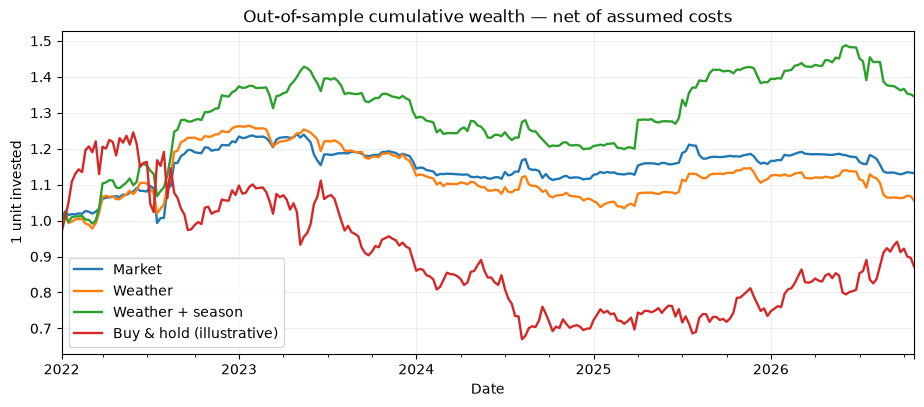

H3: net Weather − net Market weekly return, HAC estimate:


,mean,t_HAC,p_two_sided
H3,-0.000279,-0.75206,0.452015


In [10]:
def pnl_from_forecast(pred, realized, cost=TRANSACTION_COST):
    # Index t represents a decision after Friday t, followed by return t -> t+1.
    position = (pred / POSITION_SCALE).clip(lower=-1, upper=1)
    turnover = position.diff().abs()
    turnover.iloc[0] = abs(position.iloc[0])  # initial entry cost
    gross = position * realized
    net = gross - cost * turnover
    return pd.DataFrame({'position': position, 'turnover': turnover, 'gross': gross, 'net': net})

backtests = {name: pnl_from_forecast(oos[name], oos['next_week_ret']) for name in FEATURES}
strategy_returns = pd.DataFrame({name: res['net'] for name, res in backtests.items()})
strategy_returns['Buy & hold (illustrative)'] = oos['next_week_ret']

def perf(weekly_returns):
    s = pd.Series(weekly_returns).dropna()
    wealth = (1.0 + s).cumprod()
    peak = wealth.cummax()
    return pd.Series({
        'Annualized return': wealth.iloc[-1] ** (52 / len(s)) - 1,
        'Annualized volatility': s.std(ddof=1) * np.sqrt(52),
        'Sharpe (rf=0)': s.mean() / s.std(ddof=1) * np.sqrt(52) if s.std(ddof=1) > 0 else np.nan,
        'Maximum drawdown': (wealth / peak - 1).min(),
    })

performance = strategy_returns.apply(perf).T
performance['Avg annual turnover'] = [
    backtests[name]['turnover'].mean() * 52 if name in backtests else 0.0
    for name in performance.index
]
display(performance.round(4))

fig, ax = plt.subplots()
(1 + strategy_returns).cumprod().plot(ax=ax, lw=1.7)
ax.set(title='Out-of-sample cumulative wealth — net of assumed costs', ylabel='1 unit invested')
plt.show()

print('H3: net Weather − net Market weekly return, HAC estimate:')
display(hac_mean(strategy_returns['Weather'] - strategy_returns['Market']).to_frame('H3').T.round(6))

In [14]:
diff = (
    strategy_returns['Weather + season']
    - strategy_returns['Market']
)

display(hac_mean(diff).to_frame('H3 interactions').T)

,mean,t_HAC,p_two_sided
H3 interactions,0.000719,1.265658,0.205635


,MSE,Sharpe,Annual return,Max drawdown
M1 Market,0.00085,0.36053,0.02596,-0.10303
M2 Market + Weather,0.00088,0.18100,0.01128,-0.18183
M3 Market + Season,0.00087,0.15819,0.01045,-0.15160
M4 Full,0.00089,0.44077,0.04066,-0.20767


TEST HAC : apport marginal de la météo


,mean,t_HAC,p_two_sided
Forecast improvement,-0.000020,-0.820983,0.411656
Trading improvement,0.000584,1.044780,0.296125


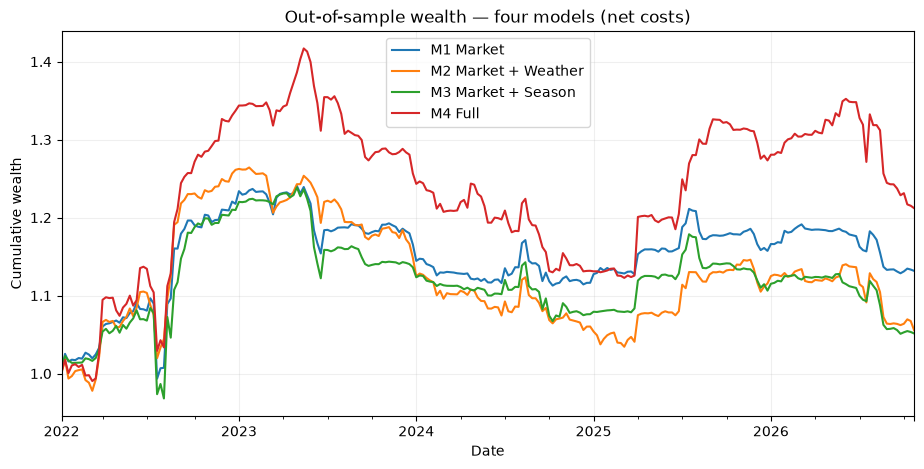

In [15]:
# ============================================================
# TEST : valeur ajoutée de la météo après contrôle saisonnier
# ============================================================

df = data.copy()

# Interactions marché × saison agricole
market_variables = [
    'ret_1w', 'ret_2w_lagged',
    'momentum_4w', 'volatility_8w'
]

market_season_cols = []
for col in market_variables:
    name = f'season_x_{col}'
    df[name] = df[col] * df['growing_season']
    market_season_cols.append(name)

# Quatre modèles emboîtés
models = {
    'M1 Market': market_cols,
    'M2 Market + Weather': market_cols + weather_cols,
    'M3 Market + Season': market_cols + market_season_cols,
    'M4 Full': market_cols + market_season_cols
               + weather_cols + season_cols
}

# Prévisions out-of-sample, même Ridge et même calendrier
pred = pd.DataFrame({
    name: expanding_forecast(df, cols)
    for name, cols in models.items()
})

y = df.loc[pred.index, 'next_week_ret']

# Backtests nets de coûts identiques
net = pd.DataFrame({
    name: pnl_from_forecast(pred[name], y)['net']
    for name in models
})

# Tableau comparatif
results = pd.DataFrame({
    name: {
        'MSE': ((y - pred[name])**2).mean(),
        'Sharpe': perf(net[name])['Sharpe (rf=0)'],
        'Annual return': perf(net[name])['Annualized return'],
        'Max drawdown': perf(net[name])['Maximum drawdown']
    }
    for name in models
}).T

display(results.round(5))

# Test central : M4 contre M3
# Différence de MSE > 0 : météo utile à la prévision
delta_mse = (
    (y - pred['M3 Market + Season'])**2
    - (y - pred['M4 Full'])**2
)

# Différence de PnL > 0 : météo utile au trading
delta_pnl = net['M4 Full'] - net['M3 Market + Season']

print("TEST HAC : apport marginal de la météo")
display(pd.DataFrame({
    'Forecast improvement': hac_mean(delta_mse),
    'Trading improvement': hac_mean(delta_pnl)
}).T.round(6))

# Visualisation
(1 + net).cumprod().plot(
    figsize=(11, 5),
    title='Out-of-sample wealth — four models (net costs)'
)
plt.ylabel('Cumulative wealth')
plt.show()

## 8. Economic robustness and diagnostics

A significant forecast improvement can fail to produce trading gains after turnover. Repeat the identical position rule at three cost assumptions. Finally, plot the weather anomalies and soybean price to check that the data make economic sense; descriptive co-movement is *not* predictive validity.

,Market,Weather,Weather + season,Δ annualized net mean Weather−Market
Cost (bps per unit turnover),,,,
0,0.4467,0.3004,0.7811,-0.0120
5,0.3605,0.1810,0.6764,-0.0145
10,0.2741,0.0611,0.5709,-0.0171
20,0.1008,-0.1799,0.3579,-0.0222


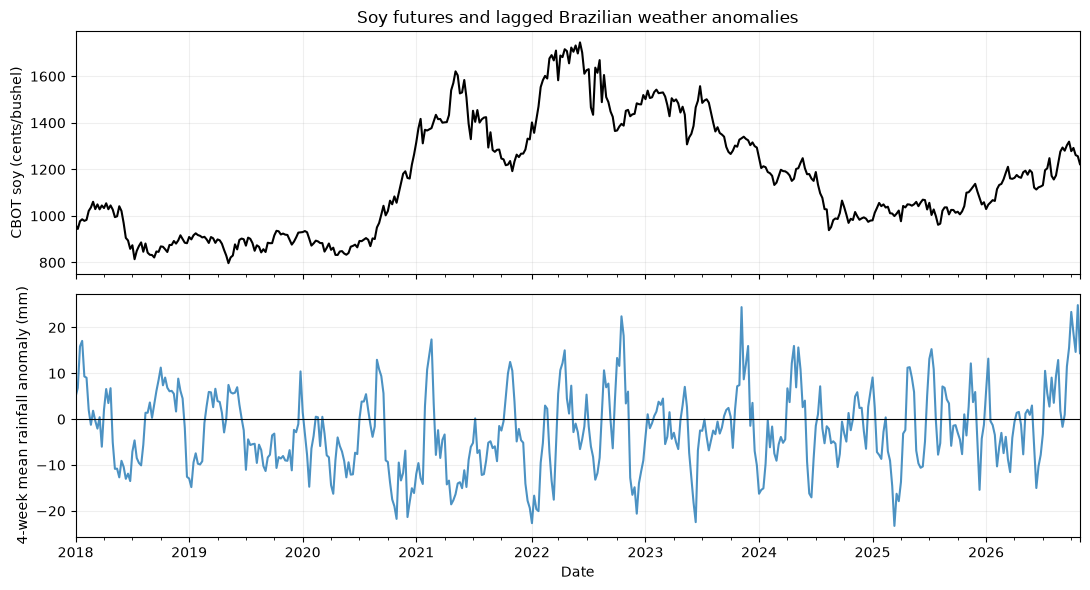

In [11]:
cost_rows=[]
for bps in [0, 5, 10, 20]:
    r = {name: pnl_from_forecast(oos[name], oos['next_week_ret'], cost=bps / 10000)['net']
         for name in FEATURES}
    cost_rows.append({'Cost (bps per unit turnover)': bps,
                      **{name: perf(ret)['Sharpe (rf=0)'] for name, ret in r.items()},
                      'Δ annualized net mean Weather−Market': 52 * (r['Weather'] - r['Market']).mean()})
robustness = pd.DataFrame(cost_rows).set_index('Cost (bps per unit turnover)')
display(robustness.round(4))

fig, axes = plt.subplots(2, 1, figsize=(11, 6), sharex=True)
weekly_price.loc['2018':].plot(ax=axes[0], color='black')
axes[0].set(ylabel='CBOT soy (cents/bushel)', title='Soy futures and lagged Brazilian weather anomalies')
X_weather.loc['2018':, 'lagged_Brazil_rain_4w'].plot(ax=axes[1], label='Rain anomaly (mm)', alpha=.8)
axes[1].axhline(0, color='black', linewidth=.8)
axes[1].set(ylabel='4-week mean rainfall anomaly (mm)')
plt.tight_layout(); plt.show()

## 9. Interpretation checklist (write your own conclusion after execution)

Read the results in this order:

1. **H1:** Is Weather MSE *lower* than Market MSE? Is the HAC test robust, or is the apparent difference within sampling noise? Also compare to forecasting zero.
2. **H2:** Is incremental predictability concentrated in the predefined growing-season months? Does explicitly interacting weather with season help in the *same* OOS window?
3. **H3:** Does Weather outperform Market **net of costs**, and does this persist when costs increase? Report the difference, not only an isolated Sharpe ratio.
4. **Caveats:** Price series is a vendor's potentially unadjusted continuous CBOT futures proxy; meteorology represents five point locations rather than acreage-weighted crop production; reanalysis is revised ex post; fixed 2014–2020 climatology is known by test start; possible cross-commodity/global macro drivers and anticipatory weather forecasts are omitted; many tests have low power; signal-to-execution timing is simplified.

**Recommended follow-up (not silently included in the principal test):** regional rainfall stress during flowering/pod filling, production-weighted locations using IBGE acreage, CEPEA domestic prices, a tradable rolled futures series, and ECMWF forecast data with *historical publication timestamps* instead of revised reanalysis.

In [12]:
print('OOS summary (do not infer significance from this line alone):')
print('H1 ΔMSE =', round(h1_loss_diff.mean(), 8), '(>0 supports incremental forecasting)')
print('H2 growing-season ΔMSE =', round(h2_table.iloc[0, 1], 8),
      '; outside-season ΔMSE =', round(h2_table.iloc[1, 1], 8))
print('H3 Δnet mean weekly return =',
      round((strategy_returns['Weather'] - strategy_returns['Market']).mean(), 6),
      '(>0 supports added trading value under assumptions)')

OOS summary (do not infer significance from this line alone):
H1 ΔMSE = -3.349e-05 (>0 supports incremental forecasting)
H2 growing-season ΔMSE = -8.044e-05 ; outside-season ΔMSE = 9.51e-06
H3 Δnet mean weekly return = -0.000279 (>0 supports added trading value under assumptions)


In [13]:
RUN_SKFIN = False
if RUN_SKFIN:
    from sklearn.base import BaseEstimator, TransformerMixin
    from skfin.backtesting import Backtester
    from skfin.estimators import Ridge as SkfinRidge

    class ForecastToPosition(BaseEstimator, TransformerMixin):
        def __init__(self, scale=POSITION_SCALE):
            self.scale = scale
        def fit(self, X, y=None):
            return self
        def transform(self, X):
            return np.clip(np.asarray(X) / self.scale, -1, 1)

    # skfin needs a 2-D target and an aligned underlying return series.
    common_ret = data[['next_week_ret']].rename(columns={'next_week_ret': 'Soy'})
    estim = make_pipeline(StandardScaler(), SkfinRidge(), ForecastToPosition())
    bt = Backtester(estim, max_train_size=None, test_size=REFIT_EVERY,
                    pred_lag=1, start_date=TEST_START)
    skfin_pnl = bt.train(data[FEATURES['Weather']], common_ret, common_ret)
    display(skfin_pnl.tail())

## Tests supplémentaires

## Sources, reproducibility and attribution

- Course methodology: [S. Champonnois, `skfin`](https://github.com/schampon/skfin) (walk-forward evaluation, ML trading backtests).
- Historical weather: [Open-Meteo Historical Weather API](https://open-meteo.com/en/docs/historical-weather-api), ECMWF/ERA5 model (daily reanalysis, publication lag, revision risk).
- Commodity prices: [Yahoo Finance — ZS=F](https://finance.yahoo.com/quote/ZS=F/), fetched by [`yfinance`](https://github.com/ranaroussi/yfinance). Continuous futures construction and Yahoo availability are not guaranteed.

**Contribution statement required by the course:** fill in the names, distinct contributions of each of the **two students**, and the parts produced, checked or adapted with AI assistance before submission. Do not submit this placeholder unchanged.